In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
import pandas as pd
from datetime import datetime
from pathlib import Path
# -----------------------------------
# EXPERIMENT DETAILS FUNCTION
# -----------------------------------
def addRecord(accuracy_val,accuracy_train,changes,x_train,x_val,model='LogisticRegression'):
    results_row = {
        "accuracy_val": accuracy_val,
        "accuracy_train": accuracy_train,
        "timestamp": datetime.now(),
        "changes":changes,

        # useful extra columns
        "num_features": x_train.shape[1],
        "train_size": len(x_train),
        "val_size": len(x_val),
        "model": model
    }
    results_path = "results.csv"

    if Path(results_path).exists():

        results_df = pd.read_csv(results_path)

        # auto increment id
        next_id = len(results_df) + 1

        results_row["id"] = next_id

        results_df = pd.concat(
            [
                results_df,
                pd.DataFrame([results_row])
            ],
            ignore_index=True
        )
    else:
        results_row["id"] = 1

        results_df = pd.DataFrame([results_row])

    results_df = results_df[
        [
            "id",
            "changes",
            "accuracy_val",
            "accuracy_train",
            "num_features",
            "train_size",
            "val_size",
            "model",
            "timestamp"
        ]
    ]

    results_df.to_csv(
        results_path,
        index=False
    )

    print("\nResults saved to results.csv")


In [13]:
og_data = pd.read_csv("student_exam_performance_dataset.csv")

og_data.head(10)

,student_id,gender,age,parental_education,family_income,internet_access,study_environment,study_hours_per_day,attendance_rate,sleep_hours,...,online_courses_completed,tutoring,math_score,reading_score,writing_score,science_score,final_exam_score,previous_gpa,pass_fail,grade_category
0,S00001,Male,17,High School,Medium,Yes,Quiet,2.98,96.5,6.05,...,1,Yes,42.8,62.4,54.8,51.8,49.1,2.44,Fail,F
1,S00002,Female,18,High School,Low,Yes,Quiet,4.45,95.7,6.96,...,0,Yes,77.9,73.5,64.4,61.6,70.1,2.79,Pass,C
2,S00003,Male,17,High School,Medium,No,Quiet,3.75,76.0,7.02,...,4,Yes,53.5,38.3,36.3,47.1,42.2,1.49,Fail,F
3,S00004,Male,18,Bachelor,Medium,Yes,Quiet,2.03,72.6,6.23,...,4,No,28.3,23.5,32.0,39.0,31.9,1.34,Fail,F
4,S00005,Male,18,Bachelor,Medium,Yes,Quiet,5.14,87.3,8.54,...,0,No,74.7,54.9,73.6,55.5,66.4,2.60,Pass,C
5,S00006,Female,17,Master,Medium,Yes,Quiet,1.16,92.0,8.16,...,2,No,40.3,42.2,44.1,30.0,40.9,1.61,Fail,F
6,S00007,Male,16,High School,High,Yes,Quiet,3.33,74.2,7.34,...,1,No,52.1,48.4,49.4,47.8,47.1,1.35,Fail,F
7,S00008,Male,18,Bachelor,Low,Yes,Moderate,2.01,88.0,6.58,...,4,No,45.6,57.1,47.4,67.0,57.0,2.52,Pass,D
8,S00009,Male,17,Master,Medium,Yes,Moderate,1.22,70.4,7.96,...,2,No,23.9,26.9,32.3,32.8,30.2,1.20,Fail,F
9,S00010,Female,15,Master,Low,Yes,Quiet,1.64,95.6,7.51,...,2,Yes,59.6,46.2,68.0,48.3,54.8,2.02,Pass,D


In [14]:
data = og_data.copy()

cat_columns = ['gender','parental_education','family_income','study_environment']
bin_columns = ['internet_access','tutoring']

data = data.join(pd.get_dummies(data[cat_columns],drop_first=False,dtype=float))

for col in bin_columns:
    data[col] = (data[col] == 'Yes').astype(float)

data.drop(columns=cat_columns,inplace=True)

In [15]:
data.drop(columns=['student_id','math_score','reading_score','writing_score','science_score','final_exam_score','grade_category'],inplace=True)

data.pass_fail = (data['pass_fail'] == 'Pass').astype(float)

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             10000 non-null  int64  
 1   internet_access                 10000 non-null  float64
 2   study_hours_per_day             10000 non-null  float64
 3   attendance_rate                 10000 non-null  float64
 4   sleep_hours                     10000 non-null  float64
 5   social_media_hours              10000 non-null  float64
 6   assignment_completion_rate      10000 non-null  float64
 7   participation_score             10000 non-null  float64
 8   online_courses_completed        10000 non-null  int64  
 9   tutoring                        10000 non-null  float64
 10  previous_gpa                    10000 non-null  float64
 11  pass_fail                       10000 non-null  float64
 12  gender_Female                   10000 non-nu

In [16]:
data["study_efficiency"] = (
    data["study_hours_per_day"] *
    data["attendance_rate"]
)
data["productivity_score"] = (
    data["assignment_completion_rate"] +
    data["participation_score"]
) / 2

data["distraction_ratio"] = (
    data["social_media_hours"] /
    (data["study_hours_per_day"] + 1)
)
data["healthy_score"] = (
    data["sleep_hours"] +
    data["attendance_rate"]/10 +
    data["study_hours_per_day"]
)
data["support_score"] = (
    data["tutoring"] +
    data["online_courses_completed"]
)
data["effort_vs_gpa"] = (
    data["study_hours_per_day"] *
    data["assignment_completion_rate"]
) / (data["previous_gpa"] + 1)

In [17]:
# corr_matrix = data.corr(numeric_only=True)
# plt.figure(figsize=(15,8))
# sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
# # Add a title
# plt.title("Correlation Matrix of Housing data")
# # Display the plot
# plt.show()

In [18]:

x = data.drop(['pass_fail'],axis=1)
y = data['pass_fail']


In [19]:
from sklearn.preprocessing import PolynomialFeatures

features = [
    "study_hours_per_day",
    "attendance_rate",
    "previous_gpa"
]

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

x_poly = poly.fit_transform(x[features])

poly_names = poly.get_feature_names_out(features)

In [20]:
x.drop(columns=features,inplace=True)

x = x.join(pd.DataFrame(x_poly,columns=poly_names))
x.head()

,age,internet_access,sleep_hours,social_media_hours,assignment_completion_rate,participation_score,online_courses_completed,tutoring,gender_Female,gender_Male,...,effort_vs_gpa,study_hours_per_day,attendance_rate,previous_gpa,study_hours_per_day^2,study_hours_per_day attendance_rate,study_hours_per_day previous_gpa,attendance_rate^2,attendance_rate previous_gpa,previous_gpa^2
0,17,1.0,6.05,0.1,80.5,68.7,1,1.0,0.0,1.0,...,69.735465,2.98,96.5,2.44,8.8804,287.570,7.2712,9312.25,235.460,5.9536
1,18,1.0,6.96,2.9,70.9,92.6,0,1.0,1.0,0.0,...,83.246702,4.45,95.7,2.79,19.8025,425.865,12.4155,9158.49,267.003,7.7841
2,17,0.0,7.02,2.4,77.6,45.8,4,1.0,0.0,1.0,...,116.867470,3.75,76.0,1.49,14.0625,285.000,5.5875,5776.00,113.240,2.2201
3,18,1.0,6.23,3.5,63.5,72.9,4,0.0,0.0,1.0,...,55.087607,2.03,72.6,1.34,4.1209,147.378,2.7202,5270.76,97.284,1.7956
4,18,1.0,8.54,2.1,71.8,55.7,0,0.0,0.0,1.0,...,102.514444,5.14,87.3,2.60,26.4196,448.722,13.3640,7621.29,226.980,6.7600


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

x = pd.DataFrame(x_scaled,columns=x.columns)

In [28]:
from sklearn.model_selection import train_test_split


x_train_val, x_test, y_train_val, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train_val,y_train_val,test_size=0.2,random_state=42)

In [29]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(x_train,y_train)



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [30]:
from sklearn.metrics import accuracy_score


def get_Accuracy(y_prob,y_true,threshold=0.75):
    y_pred =  (y_prob >= threshold).astype(int)
    
    return accuracy_score(y_true=y_true,y_pred=y_pred),y_pred

In [ ]:

val_prob = model.predict_proba(x_val)[:, 1]
train_prob = model.predict_proba(x_train)[:, 1]

accuracy_val,val_pred  = get_Accuracy(val_prob,y_val,threshold=0.35810934964023017)
accuracy_train,train_pred  = get_Accuracy(train_prob,y_train,threshold=0.35810934964023017)

print(f"Accuracy Score of training set is: {accuracy_train}")
print(f"Accuracy Score of Validation set is: {accuracy_val}")
addRecord(accuracy_val=accuracy_val,accuracy_train=accuracy_train,changes="updating normal threshold to 0.35810934964023017 (got by using precision-recall curve)",
          x_train=x_train,x_val=x_val,model="LogisiticRegression")

Accuracy Score of training set is: 0.85625
Accuracy Score of Validation set is: 0.86

Results saved to results.csv


In [32]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)


f1_scores = 2 * (precision * recall) / (precision + recall)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print(best_threshold)

0.35810934964023017


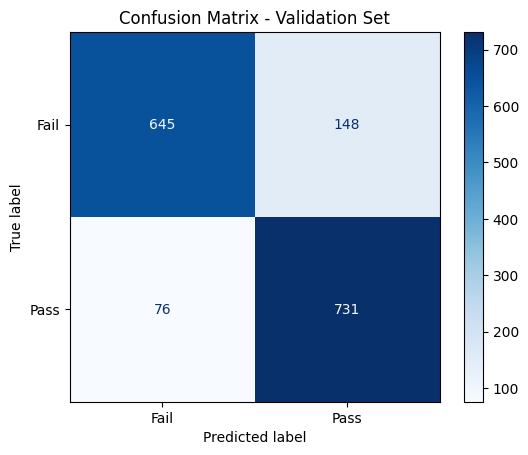

Confusion Matrix:
[[645 148]
 [ 76 731]]

True Negatives (TN): 645
False Positives (FP): 148
False Negatives (FN): 76
True Positives (TP): 731


In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix for validation set
cm = confusion_matrix(y_val, val_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail', 'Pass'])  # Adjust labels based on your target
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - Validation Set')
plt.show()

# Print confusion matrix values
print("Confusion Matrix:")
print(cm)
print("\nTrue Negatives (TN):", cm[0,0])
print("False Positives (FP):", cm[0,1])
print("False Negatives (FN):", cm[1,0])
print("True Positives (TP):", cm[1,1])